<a href="https://colab.research.google.com/github/KarlaMichelleSorianoSanhez/Simulacion-II/blob/main/Ecuaci%C3%B3n_de_Black_Scholes%2C_m%C3%A9todo_anal%C3%ADtico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <center><font color="#17365D">Ecuación de Black-Scholes. Método analítico</font></center>

## <center>Actividad 4</center>

<center>

**Materia:** Simulación II

**Nombre:** Karla Michelle Soriano Sánchez

**Fecha:** 26 de noviembre de 2026

</center>

## <font color="#17365D">Importación de la biblioteca y definición de variables</font>

Utilizamos SymPy para realizar las derivaciones,
sustituciones e integraciones necesarias para obtener
la solución analítica de la ecuación de Black-Scholes.

In [1]:
import sympy as sp
from IPython.display import display

# Presentación de las expresiones matemáticas
sp.init_printing()

# Definimos las variables y los parámetros simbólicos
S, E, sigma, T, tau = sp.symbols(
    'S E sigma T tau', positive=True
)

t, x, r, q, alpha, beta = sp.symbols(
    't x r q alpha beta', real=True
)

# Definimos las funciones de las transformaciones
V = sp.Function('V')
W = sp.Function('W')
Z = sp.Function('Z')
u = sp.Function('u')

## <font color="#17365D">1. Transformación del tiempo</font>

Partimos de la ecuación de Black-Scholes para una acción
que paga dividendos de forma continua:

$$
\frac{\partial V}{\partial t}
+\frac{1}{2}\sigma^2S^2\frac{\partial^2V}{\partial S^2}
+(r-q)S\frac{\partial V}{\partial S}
-rV=0.
\tag{1}
$$

Con condición terminal

$$
V(S,T)=\overline{V}(S),
\qquad S>0,\quad t\in[0,T].
$$

Realizamos el cambio de variable

$$
\tau=T-t,\qquad dt=-d\tau,
$$

e introducimos la función

$$
W(S,\tau)=V(S,T-\tau).
$$

Por la regla de la cadena,

$$
\frac{\partial V}{\partial t}
=-\frac{\partial W}{\partial\tau},
\qquad
\frac{\partial V}{\partial S}
=\frac{\partial W}{\partial S},
\qquad
\frac{\partial^2V}{\partial S^2}
=\frac{\partial^2W}{\partial S^2}.
$$

Sustituimos estas expresiones en la ecuación (1)
y despejamos la derivada respecto a $\tau$.

In [2]:
# diff() calcula las derivadas simbólicas
ecuacion_V = (
    sp.diff(V(S,t),t)
    + sigma**2*S**2/2 * sp.diff(V(S,t),S,2)
    + (r-q)*S*sp.diff(V(S,t),S)
    - r*V(S,t)
)

# subs() permite sustituir las derivadas
ecuacion_W = ecuacion_V.subs({
    sp.diff(V(S,t),t): -sp.diff(W(S,tau),tau),
    sp.diff(V(S,t),S): sp.diff(W(S,tau),S),
    sp.diff(V(S,t),S,2): sp.diff(W(S,tau),S,2),
    V(S,t): W(S,tau)
}, simultaneous=True)

# solve() despeja la derivada respecto a tau
resultado_W = sp.solve(
    ecuacion_W, sp.diff(W(S,tau),tau)
)[0]

display(sp.Eq(sp.diff(W(S,tau),tau), resultado_W))

                     2                                                          
               2  2 ∂                                                           
              S ⋅σ ⋅───(W(S, τ))                                                
                      2                                                         
∂                   ∂S                 ∂                 ∂                      
──(W(S, τ)) = ────────────────── - S⋅q⋅──(W(S, τ)) + S⋅r⋅──(W(S, τ)) - r⋅W(S, τ)
∂τ                    2                ∂S                ∂S                     

In [ ]:
Con esta transformación, la condición terminal se
convierte en la condición inicial

$$
W(S,0)=\overline{V}(S).
$$

## <font color="#17365D">2. Transformación logarítmica del precio de la acción subyacente</font>

Realizamos las sustituciones

$$
S=e^x,\qquad x=\ln S,
$$

e introducimos la función

$$
Z(x,\tau)=W(e^x,\tau).
$$

De manera equivalente,

$$
W(S,\tau)=Z(\ln S,\tau).
$$

Aplicando la regla de la cadena, obtenemos

$$
\frac{\partial W}{\partial S}
=\frac{1}{S}\frac{\partial Z}{\partial x},
$$

$$
\frac{\partial^2W}{\partial S^2}
=\frac{1}{S^2}
\left(
\frac{\partial^2Z}{\partial x^2}
-\frac{\partial Z}{\partial x}
\right),
$$

$$
\frac{\partial W}{\partial\tau}
=\frac{\partial Z}{\partial\tau}.
$$

Sustituimos las derivadas en la ecuación obtenida
en el paso anterior.

In [3]:
# Definimos la transformación logarítmica
W_log = Z(sp.log(S),tau)

# Calculamos las derivadas
W_S = sp.diff(W_log,S)
W_SS = sp.diff(W_log,S,2)
W_tau = sp.diff(W_log,tau)

# Sustituimos las derivadas en la ecuación del paso 1
ecuacion_Z = (
    sp.diff(W(S,tau),tau) - resultado_W
).subs({
    sp.diff(W(S,tau),S): W_S,
    sp.diff(W(S,tau),S,2): W_SS,
    sp.diff(W(S,tau),tau): W_tau,
    W(S,tau): W_log
}, simultaneous=True)

# Sustituimos S = exp(x) y simplificamos
ecuacion_Z = sp.simplify(
    ecuacion_Z.subs(S,sp.exp(x)).doit()
)

# Despejamos la derivada respecto a tau
resultado_Z = sp.solve(
    ecuacion_Z, sp.diff(Z(x,tau),tau)
)[0]

# collect() agrupa los términos de la ecuación
resultado_Z = sp.collect(
    resultado_Z, sp.diff(Z(x,tau),x)
)

display(sp.Eq(sp.diff(Z(x,tau),tau), resultado_Z))

                               2                                      
                            2 ∂                                       
                           σ ⋅───(Z(x, τ))                            
                                2            ⎛          2⎞            
∂                             ∂x             ⎜         σ ⎟ ∂          
──(Z(x, τ)) = -r⋅Z(x, τ) + ─────────────── + ⎜-q + r - ──⎟⋅──(Z(x, τ))
∂τ                                2          ⎝         2 ⎠ ∂x         

La ecuación obtenida tiene coeficientes constantes y
su condición inicial es

$$
Z(x,0)=\overline{V}(e^x),
$$

donde $x\in(-\infty,\infty)$ y $\tau\in[0,T]$.

## <font color="#17365D">3. Transformación a la ecuación en derivadas parciales parabólica</font>

Para eliminar los términos de orden inferior, utilizamos
la transformación exponencial

$$
u(x,\tau)=e^{\alpha x+\beta\tau}Z(x,\tau).
$$

Despejando,

$$
Z(x,\tau)=e^{-\alpha x-\beta\tau}u(x,\tau).
$$

Calculamos las derivadas:

$$
\frac{\partial Z}{\partial\tau}
=e^{-\alpha x-\beta\tau}
\left(\frac{\partial u}{\partial\tau}-\beta u\right),
$$

$$
\frac{\partial Z}{\partial x}
=e^{-\alpha x-\beta\tau}
\left(\frac{\partial u}{\partial x}-\alpha u\right),
$$

$$
\frac{\partial^2Z}{\partial x^2}
=e^{-\alpha x-\beta\tau}
\left(
\frac{\partial^2u}{\partial x^2}
-2\alpha\frac{\partial u}{\partial x}
+\alpha^2u
\right).
$$

Sustituimos estas expresiones en la ecuación del paso 2
y cancelamos el factor exponencial.

In [4]:
# Definimos la transformación exponencial
Z_exp = sp.exp(-alpha*x-beta*tau)*u(x,tau)

# Calculamos las derivadas
Z_tau = sp.diff(Z_exp,tau)
Z_x = sp.diff(Z_exp,x)
Z_xx = sp.diff(Z_exp,x,2)

# Sustituimos en la ecuación anterior
ecuacion_u = (
    sp.diff(Z(x,tau),tau) - resultado_Z
).subs({
    sp.diff(Z(x,tau),tau): Z_tau,
    sp.diff(Z(x,tau),x): Z_x,
    sp.diff(Z(x,tau),x,2): Z_xx,
    Z(x,tau): Z_exp
}, simultaneous=True)

# Cancelamos el factor exponencial
# expand() desarrolla los productos algebraicos
ecuacion_u = sp.expand(
    sp.simplify(ecuacion_u/sp.exp(-alpha*x-beta*tau))
)

# Agrupamos los términos de orden inferior
display(sp.Eq(
    sp.collect(ecuacion_u, [
        sp.diff(u(x,tau),x), u(x,tau)
    ]), 0
))

      2                                                                        ↪
   2 ∂                                                                         ↪
  σ ⋅───(u(x, τ))                                                              ↪
       2            ⎛                2⎞               ⎛   2  2                 ↪
     ∂x             ⎜   2           σ ⎟ ∂             ⎜  α ⋅σ                α ↪
- ─────────────── + ⎜α⋅σ  + q - r + ──⎟⋅──(u(x, τ)) + ⎜- ───── - α⋅q + α⋅r - ─ ↪
         2          ⎝               2 ⎠ ∂x            ⎝    2                   ↪

↪                                       
↪                                       
↪                                       
↪   2        ⎞                          
↪ ⋅σ         ⎟           ∂              
↪ ─── - β + r⎟⋅u(x, τ) + ──(u(x, τ)) = 0
↪ 2          ⎠           ∂τ             

### Determinación de las constantes $\alpha$ y $\beta$

Igualamos a cero los coeficientes de
$\frac{\partial u}{\partial x}$ y $u$:

$$
\sigma^2\alpha-r+q+\frac{\sigma^2}{2}=0,
$$

$$
-\frac{\sigma^2}{2}\alpha^2
+\alpha\left(r-q-\frac{\sigma^2}{2}\right)
+r-\beta=0.
$$

Resolvemos el sistema para determinar $\alpha$ y $\beta$.

In [5]:
# coeff() extrae los coeficientes de los términos
coef_ux = ecuacion_u.coeff(sp.diff(u(x,tau),x))
coef_u = ecuacion_u.coeff(u(x,tau))

# Resolvemos el sistema de ecuaciones
constantes = sp.solve(
    [coef_ux, coef_u], [alpha,beta], dict=True
)[0]

# Mostramos las constantes obtenidas
display(sp.Eq(alpha, constantes[alpha]))
display(sp.Eq(beta, constantes[beta]))

# Sustituimos las constantes en la ecuación
ecuacion_calor = sp.simplify(
    ecuacion_u.subs(constantes)
)

display(sp.Eq(ecuacion_calor,0))

     ⎛             2⎞ 
    -⎝2⋅q - 2⋅r + σ ⎠ 
α = ──────────────────
              2       
           2⋅σ        

       2                2      2        2    4
    4⋅q  - 8⋅q⋅r + 4⋅q⋅σ  + 4⋅r  + 4⋅r⋅σ  + σ 
β = ──────────────────────────────────────────
                          2                   
                       8⋅σ                    

      2                            
   2 ∂                             
  σ ⋅───(u(x, τ))                  
       2                           
     ∂x             ∂              
- ─────────────── + ──(u(x, τ)) = 0
         2          ∂τ             

Las constantes obtenidas son

$$
\alpha=\frac{r-q-\frac{\sigma^2}{2}}{\sigma^2},
$$

$$
\beta=r+
\frac{\left(r-q-\frac{\sigma^2}{2}\right)^2}
{2\sigma^2}.
$$

Al sustituirlas, obtenemos la ecuación del calor:

$$
\boxed{
\frac{\partial u}{\partial\tau}
-\frac{\sigma^2}{2}\frac{\partial^2u}{\partial x^2}=0
}
$$

Esta ecuación corresponde a la ecuación parabólica

$$
\frac{\partial u}{\partial\tau}
-a^2\frac{\partial^2u}{\partial x^2}=0,
\tag{2}
$$

con $a^2=\frac{\sigma^2}{2}$ y condición inicial

$$
u(x,0)=e^{\alpha x}\overline{V}(e^x).
$$

## <font color="#17365D">4. Aplicación de la fórmula de Green</font>

La solución de la ecuación del calor está dada por

$$
u(x,\tau)=
\frac{1}{\sqrt{2\sigma^2\pi\tau}}
\int_{-\infty}^{\infty}
e^{-\frac{(x-s)^2}{2\sigma^2\tau}}
u(s,0)\,ds.
$$

Sustituimos la condición inicial

$$
u(s,0)=e^{\alpha s}\overline{V}(e^s).
$$

Realizamos las sustituciones inversas

$$
u\longrightarrow Z\longrightarrow W\longrightarrow V.
$$

De esta manera,

$$
V(S,T-\tau)=
e^{-\beta\tau}e^{-\alpha\ln S}u(\ln S,\tau).
$$

Por lo tanto,

$$
V(S,T-\tau)=
\frac{e^{-\beta\tau}S^{-\alpha}}
{\sqrt{2\sigma^2\pi\tau}}
\int_{-\infty}^{\infty}
e^{-\frac{(\ln S-s)^2}{2\sigma^2\tau}}
e^{\alpha s}\overline{V}(e^s)\,ds.
\tag{3}
$$

In [6]:
# Variable de integración y condición terminal
s = sp.symbols('s', real=True)
V_bar = sp.Function(r'\overline{V}')

# Núcleo de la fórmula de Green
G = (
    sp.exp(-(x-s)**2/(2*sigma**2*tau))
    / sp.sqrt(2*sigma**2*sp.pi*tau)
)

# Condición inicial
u0 = sp.exp(alpha*s)*V_bar(sp.exp(s))

# Integral() representa una integral simbólica
solucion_u = sp.Integral(G*u0, (s,-sp.oo,sp.oo))

display(sp.Eq(u(x,tau), solucion_u))

# Regresamos a las variables originales
solucion_V = (
    sp.exp(-beta*tau)*S**(-alpha)
    * solucion_u.subs(x,sp.log(S))
)

display(sp.Eq(V(S,T-tau), solucion_V))

          ∞                                          
          ⌠                                          
          ⎮                                     2    
          ⎮                            -(-s + x)     
          ⎮                            ───────────   
          ⎮                                 2        
          ⎮                 ⎛ s⎞  α⋅s    2⋅σ ⋅τ      
          ⎮  √2⋅\overline{V}⎝ℯ ⎠⋅ℯ   ⋅ℯ              
u(x, τ) = ⎮  ───────────────────────────────────── ds
          ⎮                2⋅√π⋅σ⋅√τ                 
          ⌡                                          
          -∞                                         

                        ∞                                               
                        ⌠                                               
                        ⎮                                          2    
                        ⎮                            -(-s + log(S))     
                        ⎮                            ────────────────   
                        ⎮                                    2          
                        ⎮                 ⎛ s⎞  α⋅s       2⋅σ ⋅τ        
               -α  -β⋅τ ⎮  √2⋅\overline{V}⎝ℯ ⎠⋅ℯ   ⋅ℯ                   
V(S, T - τ) = S  ⋅ℯ    ⋅⎮  ────────────────────────────────────────── ds
                        ⎮                  2⋅√π⋅σ⋅√τ                    
                        ⌡                                               
                        -∞                                              

### Condición terminal de una opción europea de compra

Para una opción de compra (call), tenemos

$$
\overline{V}(S)=(S-E)^+.
$$

Por lo tanto,

$$
\overline{V}(e^s)=
\begin{cases}
e^s-E, & s\geq\ln E,\\
0, & s<\ln E.
\end{cases}
$$

Sustituyendo en la ecuación (3),

$$
V(S,T-\tau)=
\frac{e^{-\beta\tau}S^{-\alpha}}
{\sqrt{2\sigma^2\pi\tau}}
\int_{\ln E}^{\infty}
e^{-\frac{(\ln S-s)^2}{2\sigma^2\tau}}
e^{\alpha s}(e^s-E)\,ds.
$$

Realizamos el cambio de variable

$$
y=s-\ln S,\qquad ds=dy.
$$

Separando las integrales, obtenemos

$$
\begin{aligned}
V(S,T-\tau)
=\frac{e^{-\beta\tau}}{\sqrt{2\sigma^2\pi\tau}}
\Bigg[
&S\int_{\ln(E/S)}^\infty
e^{-\frac{y^2}{2\sigma^2\tau}+(\alpha+1)y}\,dy\\
-&E\int_{\ln(E/S)}^\infty
e^{-\frac{y^2}{2\sigma^2\tau}+\alpha y}\,dy
\Bigg].
\end{aligned}
$$

In [7]:
# Variable del cambio de integración
y = sp.symbols('y', real=True)

# Integrales obtenidas después del cambio de variable
I1 = sp.Integral(
    sp.exp(-y**2/(2*sigma**2*tau)+(alpha+1)*y),
    (y,sp.log(E/S),sp.oo)
)

I2 = sp.Integral(
    sp.exp(-y**2/(2*sigma**2*tau)+alpha*y),
    (y,sp.log(E/S),sp.oo)
)

# Expresión de la solución
V_integral = (
    sp.exp(-beta*tau)
    / sp.sqrt(2*sp.pi*sigma**2*tau)
    * (S*I1-E*I2)
)

display(sp.Eq(V(S,T-tau), V_integral))

                 ⎛      ∞                           ∞                          ↪
                 ⎜      ⌠                           ⌠                          ↪
                 ⎜      ⎮              2            ⎮                    2     ↪
                 ⎜      ⎮             y             ⎮                   y      ↪
                 ⎜      ⎮     α⋅y - ──────          ⎮     y⋅(α + 1) - ──────   ↪
                 ⎜      ⎮              2            ⎮                    2     ↪
                 ⎜      ⎮           2⋅σ ⋅τ          ⎮                 2⋅σ ⋅τ   ↪
              √2⋅⎜- E⋅  ⎮    ℯ             dy + S⋅  ⎮    ℯ                   d ↪
                 ⎜      ⌡                           ⌡                          ↪
                 ⎜       ⎛E⎞                         ⎛E⎞                       ↪
                 ⎜    log⎜─⎟                      log⎜─⎟                       ↪
                 ⎝       ⎝S⎠                         ⎝S⎠                       ↪
V(S, T - τ) = ──────────────

### Evaluación de las integrales

Completamos cuadrados en los exponentes:

$$
-\frac{y^2}{2\sigma^2\tau}+(\alpha+1)y
=
-\frac{[y-(\alpha+1)\sigma^2\tau]^2}
{2\sigma^2\tau}
+\frac{(\alpha+1)^2\sigma^2\tau}{2},
$$

$$
-\frac{y^2}{2\sigma^2\tau}+\alpha y
=
-\frac{(y-\alpha\sigma^2\tau)^2}
{2\sigma^2\tau}
+\frac{\alpha^2\sigma^2\tau}{2}.
$$

Utilizamos la función de distribución acumulada
normal estándar:

$$
N(z)=\frac{1}{\sqrt{2\pi}}
\int_{-\infty}^{z}e^{-\frac{v^2}{2}}\,dv.
$$

Esta integral se expresa mediante la función error:

$$
N(z)=\frac{1}{2}
\left[
1+\operatorname{erf}
\left(\frac{z}{\sqrt{2}}\right)
\right].
$$

In [8]:
# Variables de la integral normal estándar
v, z = sp.symbols('v z', real=True)

# integrate() evalúa simbólicamente la integral
normal = sp.integrate(
    sp.exp(-v**2/2)/sp.sqrt(2*sp.pi),
    (v,-sp.oo,z)
)

display(sp.Eq(sp.Function('N')(z), normal))

# Definimos N a partir de la integral obtenida
def N(argumento):
    return normal.subs(z,argumento)

# Argumentos obtenidos al completar cuadrados
d1_tau = (
    sp.log(S/E)+(alpha+1)*sigma**2*tau
)/(sigma*sp.sqrt(tau))

d2_tau = (
    sp.log(S/E)+alpha*sigma**2*tau
)/(sigma*sp.sqrt(tau))

# Evaluamos las integrales mediante N
I1_evaluada = (
    sp.sqrt(2*sp.pi*sigma**2*tau)
    * sp.exp((alpha+1)**2*sigma**2*tau/2)
    * N(d1_tau)
)

I2_evaluada = (
    sp.sqrt(2*sp.pi*sigma**2*tau)
    * sp.exp(alpha**2*sigma**2*tau/2)
    * N(d2_tau)
)

# Sustituimos las integrales evaluadas
V_evaluada = V_integral.subs({
    I1: I1_evaluada,
    I2: I2_evaluada
})

display(sp.Eq(V(S,T-tau), V_evaluada))

               ⎛√2⋅z⎞
           erfc⎜────⎟
               ⎝ 2  ⎠
N(z) = 1 - ──────────
               2     

                 ⎛               ⎛        ⎛   ⎛   2        ⎛S⎞⎞⎞⎞              ↪
                 ⎜               ⎜        ⎜√2⋅⎜α⋅σ ⋅τ + log⎜─⎟⎟⎟⎟   2  2       ↪
                 ⎜               ⎜        ⎜   ⎝            ⎝E⎠⎠⎟⎟  α ⋅σ ⋅τ     ↪
                 ⎜               ⎜    erfc⎜────────────────────⎟⎟  ───────     ↪
                 ⎜               ⎜        ⎝       2⋅σ⋅√τ       ⎠⎟     2        ↪
              √2⋅⎜- √2⋅√π⋅E⋅σ⋅√τ⋅⎜1 - ──────────────────────────⎟⋅ℯ        + √ ↪
                 ⎝               ⎝                2             ⎠              ↪
V(S, T - τ) = ──────────────────────────────────────────────────────────────── ↪
                                                                             2 ↪

↪             ⎛        ⎛   ⎛ 2                ⎛S⎞⎞⎞⎞               ⎞      
↪             ⎜        ⎜√2⋅⎜σ ⋅τ⋅(α + 1) + log⎜─⎟⎟⎟⎟   2          2⎟      
↪             ⎜        ⎜   ⎝                  ⎝E⎠⎠⎟⎟  σ ⋅τ⋅(α + 1) ⎟      
↪             ⎜    erfc⎜─────────────────────

In [9]:
# Simplificamos los exponentes
exp_1 = sp.simplify(
    (-beta+(alpha+1)**2*sigma**2/2).subs(constantes)
)

exp_2 = sp.simplify(
    (-beta+alpha**2*sigma**2/2).subs(constantes)
)

display(exp_1, exp_2)

# Sustituimos las constantes y tau = T-t
d1 = sp.simplify(d1_tau.subs(constantes)).subs(tau,T-t)
d2 = sp.simplify(d2_tau.subs(constantes)).subs(tau,T-t)

# Fórmula de Black-Scholes obtenida
precio_call = (
    S*sp.exp(exp_1*(T-t))*N(d1)
    - E*sp.exp(exp_2*(T-t))*N(d2)
)

display(sp.Eq(sp.Symbol('d_1'),d1))
display(sp.Eq(sp.Symbol('d_2'),d2))
display(sp.Eq(V(S,t),precio_call))

-q

-r

                                    ⎛ 2⎞
             ⎛              2⎞      ⎜S ⎟
     (T - t)⋅⎝-2⋅q + 2⋅r + σ ⎠ + log⎜──⎟
                                    ⎜ 2⎟
                                    ⎝E ⎠
d₁ = ───────────────────────────────────
                      _______           
                2⋅σ⋅╲╱ T - t            

                                     ⎛ 2⎞
               ⎛             2⎞      ⎜S ⎟
     - (T - t)⋅⎝2⋅q - 2⋅r + σ ⎠ + log⎜──⎟
                                     ⎜ 2⎟
                                     ⎝E ⎠
d₂ = ────────────────────────────────────
                      _______            
                2⋅σ⋅╲╱ T - t             

              ⎛        ⎛   ⎛                                ⎛ 2⎞⎞⎞⎞            ↪
              ⎜        ⎜   ⎜          ⎛             2⎞      ⎜S ⎟⎟⎟⎟            ↪
              ⎜        ⎜√2⋅⎜- (T - t)⋅⎝2⋅q - 2⋅r + σ ⎠ + log⎜──⎟⎟⎟⎟            ↪
              ⎜        ⎜   ⎜                                ⎜ 2⎟⎟⎟⎟            ↪
              ⎜        ⎜   ⎝                                ⎝E ⎠⎠⎟⎟            ↪
              ⎜    erfc⎜─────────────────────────────────────────⎟⎟            ↪
              ⎜        ⎜                    _______              ⎟⎟            ↪
              ⎜        ⎝              4⋅σ⋅╲╱ T - t               ⎠⎟  -r⋅(T - t ↪
V(S, t) = - E⋅⎜1 - ───────────────────────────────────────────────⎟⋅ℯ          ↪
              ⎝                           2                       ⎠            ↪

↪       ⎛        ⎛   ⎛                               ⎛ 2⎞⎞⎞⎞            
↪       ⎜        ⎜   ⎜        ⎛              2⎞      ⎜S ⎟⎟⎟⎟            
↪       ⎜        ⎜√2⋅⎜(T - t)⋅⎝-2⋅q + 2⋅r +

Al sustituir las constantes, los exponentes se reducen a

$$
-\beta+\frac{(\alpha+1)^2\sigma^2}{2}=-q,
$$

$$
-\beta+\frac{\alpha^2\sigma^2}{2}=-r.
$$

Finalmente, con $\tau=T-t$, obtenemos la fórmula de
Black-Scholes para una opción europea de compra:

$$
\boxed{
V(S,t)=Se^{-q(T-t)}N(d_1)
-Ee^{-r(T-t)}N(d_2)
}
$$

donde

$$
d_1=
\frac{
\left(r-q+\frac{\sigma^2}{2}\right)(T-t)
+\ln\frac{S}{E}
}
{\sigma\sqrt{T-t}},
$$

$$
d_2=d_1-\sigma\sqrt{T-t}.
$$

## <font color="#17365D">5. Ejercicio</font>

### Enunciado

El precio al contado actual de la acción subyacente de IBM,
que no paga dividendos, es $S=58.5$. La volatilidad histórica
del activo se ha estimado en $\sigma=29\%$, es decir,
$\sigma=0.29$. La tasa de interés anualizada de los bonos
cupón cero es $r=4\%$, es decir, $r=0.04$.

Consideramos una opción de compra (call) con un precio
de ejercicio de $E=60$ y un vencimiento en $T=0.3$ años.

Obtener el precio de la opción $V=V(58.5,0)$.

### Solución

Identificamos los datos del problema:

$$
\begin{aligned}
S&=58.5, & E&=60,\\
\sigma&=0.29, & r&=0.04,\\
T&=0.3, & t&=0,\\
q&=0.
\end{aligned}
$$

Como la acción no paga dividendos, $q=0$, la fórmula
de Black-Scholes se reduce a

$$
V(S,t)=SN(d_1)-Ee^{-r(T-t)}N(d_2).
$$

In [10]:
# Datos del ejercicio
# Rational() permite trabajar con valores exactos
datos = {
    S: sp.Rational('58.5'),
    E: 60,
    sigma: sp.Rational('0.29'),
    r: sp.Rational('0.04'),
    T: sp.Rational('0.3'),
    t: 0,
    q: 0
}

# Sustituimos q = 0
display(sp.Eq(V(S,t),precio_call.subs(q,0)))

              ⎛        ⎛   ⎛                           ⎛ 2⎞⎞⎞⎞                 ↪
              ⎜        ⎜   ⎜          ⎛        2⎞      ⎜S ⎟⎟⎟⎟                 ↪
              ⎜        ⎜√2⋅⎜- (T - t)⋅⎝-2⋅r + σ ⎠ + log⎜──⎟⎟⎟⎟                 ↪
              ⎜        ⎜   ⎜                           ⎜ 2⎟⎟⎟⎟                 ↪
              ⎜        ⎜   ⎝                           ⎝E ⎠⎠⎟⎟                 ↪
              ⎜    erfc⎜────────────────────────────────────⎟⎟                 ↪
              ⎜        ⎜                 _______            ⎟⎟                 ↪
              ⎜        ⎝           4⋅σ⋅╲╱ T - t             ⎠⎟  -r⋅(T - t)     ↪
V(S, t) = - E⋅⎜1 - ──────────────────────────────────────────⎟⋅ℯ           + S ↪
              ⎝                        2                     ⎠                 ↪

↪  ⎛        ⎛   ⎛                        ⎛ 2⎞⎞⎞⎞
↪  ⎜        ⎜   ⎜        ⎛       2⎞      ⎜S ⎟⎟⎟⎟
↪  ⎜        ⎜√2⋅⎜(T - t)⋅⎝2⋅r + σ ⎠ + log⎜──⎟⎟⎟⎟
↪  ⎜        ⎜   ⎜                        ⎜

### Cálculo de $d_1$ y $d_2$

Sustituimos los datos del ejercicio:

$$
d_1=
\frac{
\left(0.04+\frac{(0.29)^2}{2}\right)(0.3)
+\ln\frac{58.5}{60}
}
{0.29\sqrt{0.3}},
$$

$$
d_2=d_1-0.29\sqrt{0.3}.
$$

In [11]:
# Sustituimos los datos en d1 y d2
d1_valor = d1.subs(datos)
d2_valor = d2.subs(datos)

# evalf() obtiene una aproximación numérica
print(f"d1 = {d1_valor.evalf():.8f}")
print(f"d2 = {d2_valor.evalf():.8f}")

d1 = -0.00442464
d2 = -0.16326418


### Cálculo de $N(d_1)$ y $N(d_2)$

Evaluamos la función de distribución acumulada normal
estándar en los valores obtenidos de $d_1$ y $d_2$.

In [12]:
# Evaluamos la distribución normal acumulada
N_d1 = N(d1_valor)
N_d2 = N(d2_valor)

# Mostramos los resultados con ocho decimales
print(f"N(d1) = {N_d1.evalf():.8f}")
print(f"N(d2) = {N_d2.evalf():.8f}")

N(d1) = 0.49823483
N(d2) = 0.43515522


### Cálculo del precio de la opción

Con los valores obtenidos, sustituimos en la fórmula
de Black-Scholes:

$$
V(58.5,0)\approx
58.5(0.49823483)
-60e^{-(0.04)(0.3)}(0.43515522).
$$

En el cálculo utilizamos los valores sin redondear.

In [13]:
# Evaluamos la fórmula de Black-Scholes
precio = precio_call.subs(datos)

# Mostramos el precio obtenido
print(f"V(58.5,0) = {precio.evalf():.8f}")
print(f"Precio de la opción = {precio.evalf():.2f}")

V(58.5,0) = 3.34886390
Precio de la opción = 3.35


Por lo tanto, el precio de la opción europea de compra es

$$
\boxed{V(58.5,0)\approx3.35}
$$

## <font color="#17365D">6. Representación gráfica de la solución</font>

Representamos la solución analítica mediante una superficie
tridimensional, variando el precio de la acción $S$ y el
tiempo $t$, mientras los demás parámetros permanecen constantes.

En el vencimiento utilizamos la condición terminal

$$
V(S,T)=(S-E)^+.
$$

El punto rojo representa la solución del ejercicio,
correspondiente a $S=58.5$ y $t=0$.

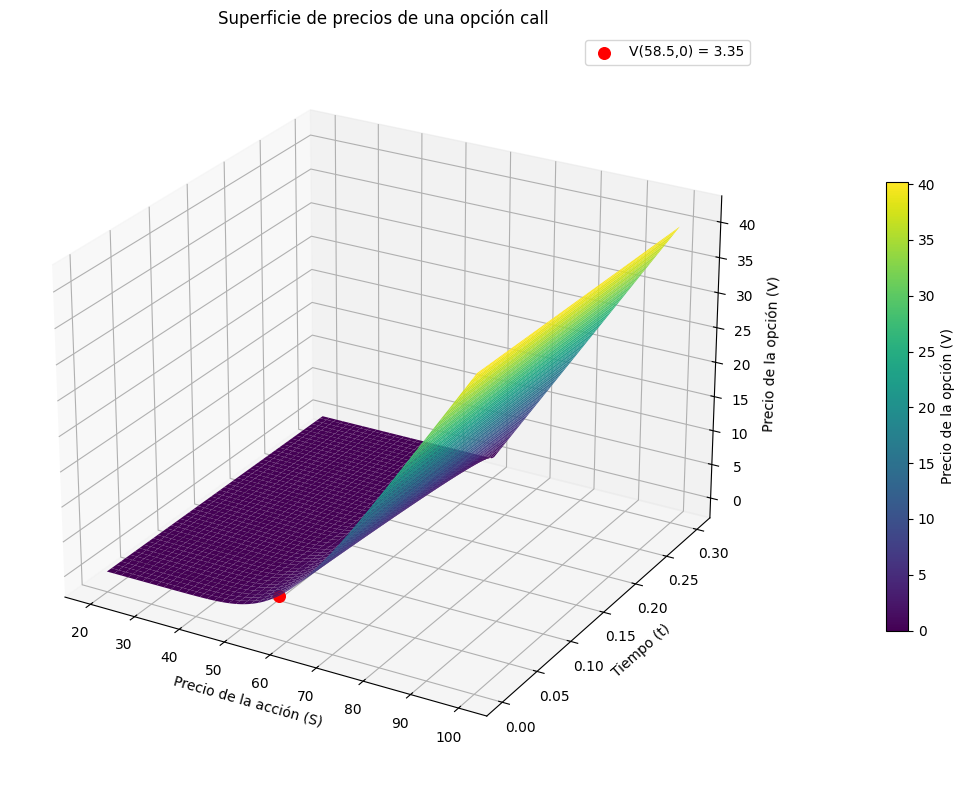

In [14]:
# Bibliotecas de apoyo para la gráfica
import numpy as np
import matplotlib.pyplot as plt

# Fijamos los parámetros, excepto S y t
parametros = {
    E: datos[E],
    sigma: datos[sigma],
    r: datos[r],
    q: datos[q],
    T: datos[T]
}

# lambdify() convierte la expresión simbólica
# en una función para realizar evaluaciones numéricas
V_funcion = sp.lambdify(
    (S,t), precio_call.subs(parametros), 'scipy'
)

# Intervalos del precio de la acción y del tiempo
S_valores = np.linspace(20,100,150)
t_valores = np.linspace(0,float(datos[T]),150)

# meshgrid() genera una malla de valores de S y t
S_malla, t_malla = np.meshgrid(S_valores,t_valores)

# Matriz para almacenar los precios de la opción
V_malla = np.zeros_like(S_malla)

# Evaluamos la solución antes del vencimiento
V_malla[:-1] = V_funcion(
    S_malla[:-1],t_malla[:-1]
)

# Aplicamos la condición terminal en t = T
V_malla[-1] = np.maximum(
    S_valores-float(datos[E]),0
)

# Creamos la gráfica tridimensional
fig = plt.figure(figsize=(11,8))
ax = fig.add_subplot(111,projection='3d')

# Graficamos la superficie
superficie = ax.plot_surface(
    S_malla,t_malla,V_malla,
    cmap='viridis',edgecolor='none'
)

# Señalamos la solución del ejercicio
ax.scatter(
    float(datos[S]),float(datos[t]),float(precio),
    color='red',s=70,
    label=f'V(58.5,0) = {float(precio):.2f}'
)

# Título y nombres de los ejes
ax.set_title('Superficie de precios de una opción call')
ax.set_xlabel('Precio de la acción (S)')
ax.set_ylabel('Tiempo (t)')
ax.set_zlabel('Precio de la opción (V)')

# Ajustamos el ángulo de visualización
ax.view_init(elev=25,azim=-60)

# Barra de colores
fig.colorbar(
    superficie,ax=ax,shrink=0.6,pad=0.12,
    label='Precio de la opción (V)'
)

ax.legend()
plt.tight_layout()
plt.show()

**Observación:**

En la superficie se observa que el precio de la opción
aumenta conforme se incrementa el precio de la acción
subyacente. Al acercarse el vencimiento, la superficie
converge a la función de pago $(S-E)^+$.

## <font color="#17365D">7. Conclusión</font>

Mediante las transformaciones de la ecuación de
Black-Scholes y la aplicación de la fórmula de Green,
obtuvimos la solución analítica para una opción europea
de compra.

Al evaluar los datos del ejercicio, obtuvimos un precio
de aproximadamente 3.35 unidades monetarias por acción.
Aunque el precio actual de la acción es menor que el
precio de ejercicio, la opción tiene un valor positivo
debido a la posibilidad de que el precio de la acción
supere los 60 al vencimiento.